# Human Activity Recognition Using Hidden Markov Models

## 1. Introduction and Project Objectives

This project investigates how smartphone motion sensors can be used to recognize four human activity states: standing, walking, jumping, and keeping the phone still.

The data were collected using Sensor Logger, which records measurements from the smartphone's accelerometer and gyroscope. The accelerometer captures changes in acceleration along three axes, while the gyroscope captures rotational movement around three axes.

The objective is to prepare the sensor data, extract meaningful features, and develop a Hidden Markov Model (HMM) that can identify activity patterns in unseen recordings.

The project includes data inspection and preprocessing, feature extraction and normalization, HMM implementation, Viterbi decoding, Baum–Welch parameter estimation, and model evaluation. The final results will be used to assess how well the model distinguishes the four activity classes.

The notebook documents each stage with explanations, code, visualizations, and interpretations of the results.

## 2. Environment Setup and Data Access

I'll imports the Python libraries required for data handling, numerical calculations, visualization, and evaluation. Google Drive is mounted so the notebook can access the collected ZIP files directly.

The original ZIP files remain in Google Drive. I'll read their contents directly instead of extracting and storing a second copy of all the sensor files.

In [1]:
# Import standard and scientific Python libraries
import os
import re
import io
import zipfile
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

print("Libraries imported successfully.")
print("Google Drive connection requested.")

Mounted at /content/drive
Libraries imported successfully.
Google Drive connection requested.


## 3. Locating the Project Data

The project data are stored in the `Sensor Data` subfolder of the main project folder. Each ZIP archive represents one recording and contains the CSV files exported by Sensor Logger.

I'll first verify that the expected folder exists before attempting to read any data. This helps me catch incorrect folder names or locations early.

In [6]:
from pathlib import Path

# Main project folder
PROJECT_DIR = Path(
    "/content/drive/MyDrive/HMM_Human_Activity_Project"
)

# Correct folder paths
SENSOR_DIR = PROJECT_DIR / "Sensor Data"
VIDEO_DIR = PROJECT_DIR / "Activity videos"

# Verify both folders
print("Sensor Data folder exists:", SENSOR_DIR.exists())
print("Activity videos folder exists:", VIDEO_DIR.exists())

# Count sensor recordings and videos
zip_files = sorted(SENSOR_DIR.glob("*.zip"))

video_extensions = {".mp4", ".mov", ".m4v", ".avi"}
video_files = [
    file for file in VIDEO_DIR.iterdir()
    if file.is_file() and file.suffix.lower() in video_extensions
]

print("\nNumber of sensor ZIP files:", len(zip_files))
print("Number of video files found:", len(video_files))

print("\nVideo filenames:")
for file in sorted(video_files):
    print("-", file.name)

Sensor Data folder exists: True
Activity videos folder exists: True

Number of sensor ZIP files: 200
Number of video files found: 4

Video filenames:
- jumping_video_01.mp4
- standing_video_01.mp4
- staystill_video_01.mp4
- walking_video_01.mp4


##4. Recording Inventory and Activity Labels

The recordings are organized into four activity classes. I'll inspect the filenames and count the recordings belonging to each class. This is an initial data-integrity check. The counts alone do not confirm that every recording contains valid sensor measurements.

In [8]:
# The four activity classes
ACTIVITIES = ["standing", "walking", "jumping", "staystill"]

# Match filenames such as standing_01.zip or jumping-50.zip
filename_pattern = re.compile(
    r"^(standing|walking|jumping|staystill)[_-]?(\d+)\.zip$",
    flags=re.IGNORECASE
)

recording_inventory = []
unrecognized_files = []

for file_path in zip_files:
    match = filename_pattern.match(file_path.name)

    if match:
        activity = match.group(1).lower()
        recording_number = int(match.group(2))

        recording_inventory.append({
            "filename": file_path.name,
            "activity": activity,
            "recording_number": recording_number,
            "path": str(file_path)
        })
    else:
        unrecognized_files.append(file_path.name)

inventory_df = pd.DataFrame(recording_inventory)

if not inventory_df.empty:
    print("Recordings per activity:")
    display(
        inventory_df["activity"]
        .value_counts()
        .reindex(ACTIVITIES, fill_value=0)
        .rename("number_of_recordings")
        .to_frame()
    )

    print("\nTotal recognized recordings:", len(inventory_df))

if unrecognized_files:
    print("\nFiles needing attention:")
    for name in unrecognized_files[:20]:
        print("-", name)

if len(inventory_df) == 0:
    print(
        "\nNo filenames matched the expected activity_number.zip format. "
        "We will adjust the filename pattern before continuing."
    )

Recordings per activity:


,number_of_recordings
activity,
standing,50
walking,50
jumping,50
staystill,50



Total recognized recordings: 200


### 5. Inspecting a Sample Sensor Recording

Each ZIP archive contains sensor measurements, recording metadata, and optional annotations. I'll inspect the CSV files to identify their column names, data formats, and initial values before designing the preprocessing pipeline.

Some files, such as `Annotation.csv`, may be empty if no annotations were recorded. These files will be identified and skipped safely during inspection without interrupting the analysis of the remaining sensor data.

In [10]:
# Inspect one recording without extracting files to Google Drive

if inventory_df.empty:
    raise ValueError(
        "No recognized recordings are available. "
        "Check the filename inventory first."
    )

sample_recording = inventory_df.iloc[0]
sample_zip_path = Path(sample_recording["path"])

print("Sample archive:", sample_zip_path.name)
print("Activity label:", sample_recording["activity"])

with zipfile.ZipFile(sample_zip_path, "r") as archive:

    # Check whether the ZIP archive is intact
    damaged_file = archive.testzip()

    if damaged_file is not None:
        raise RuntimeError(
            f"Damaged file found inside ZIP: {damaged_file}"
        )

    # Find CSV files inside the archive
    csv_members = [
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
        and not name.startswith("__MACOSX/")
    ]

    print(f"\nNumber of CSV files: {len(csv_members)}")

    empty_csv_files = []
    inspected_csv_files = []

    for member in csv_members:
        print("\n" + "=" * 65)
        print("FILE:", member)

        try:
            with archive.open(member) as file:
                sample_df = pd.read_csv(file, nrows=5)

            print("Columns:", sample_df.columns.tolist())
            display(sample_df.head(3))

            inspected_csv_files.append(member)

        except pd.errors.EmptyDataError:
            print("This CSV is empty; skipping it safely.")
            empty_csv_files.append(member)

    print("\n" + "=" * 65)
    print("Inspection summary")
    print("CSV files successfully inspected:", len(inspected_csv_files))
    print("Empty CSV files:", len(empty_csv_files))

    if empty_csv_files:
        print("Empty files identified:", empty_csv_files)

Sample archive: jumping_01.zip
Activity label: jumping

Number of CSV files: 7

FILE: Accelerometer.csv
Columns: ['time', 'seconds_elapsed', 'z', 'y', 'x']


,time,seconds_elapsed,z,y,x
0,1792833982051839700,0.139840,-0.111619,-0.224188,0.702002
1,1792833982066053600,0.154054,0.720410,-0.443458,0.622489
2,1792833982077121800,0.165122,0.826988,-0.480976,0.469447



FILE: Metadata.csv
Columns: ['version', 'device name', 'recording epoch time', 'recording time', 'recording timezone', 'platform', 'appVersion', 'device id', 'sensors', 'sampleRateMs', 'standardisation', 'platform version']


,version,device name,recording epoch time,recording time,recording timezone,platform,appVersion,device id,sensors,sampleRateMs,standardisation,platform version
0,3,TECNO KJ5,1792833981912,2026-10-24_09-26-21,Africa/Kigali,android,1.68,6d38b062-7167-4be0-a6fb-6a6e9314d634,Accelerometer|Gyroscope|Annotation|TotalAccele...,10|10||10|10|10,False,33



FILE: Gyroscope.csv
Columns: ['time', 'seconds_elapsed', 'z', 'y', 'x']


,time,seconds_elapsed,z,y,x
0,1792833982057521700,0.145522,0,0,0
1,1792833982077121800,0.165122,0,0,0
2,1792833982087162000,0.175162,0,0,0



FILE: Annotation.csv
This CSV is empty; skipping it safely.

FILE: TotalAcceleration.csv
Columns: ['time', 'seconds_elapsed', 'z', 'y', 'x']


,time,seconds_elapsed,z,y,x
0,1792833982077121800,0.165122,8.455951,5.57295,1.61805
1,1792833982087162000,0.175162,8.542050,5.54505,1.04295
2,1792833982097141000,0.185141,8.590051,5.51595,1.04295



FILE: GyroscopeUncalibrated.csv
This CSV is empty; skipping it safely.

FILE: AccelerometerUncalibrated.csv
This CSV is empty; skipping it safely.

Inspection summary
CSV files successfully inspected: 4
Empty CSV files: 3
Empty files identified: ['Annotation.csv', 'GyroscopeUncalibrated.csv', 'AccelerometerUncalibrated.csv']


##6. Recording Duration, Data Quality, and Sampling Rate
The duration and sampling rate of each recording are important for selecting an appropriate window size. Although the Sensor Logger metadata specifies a target sampling interval, the actual rate may vary because of device and operating-system behavior.

This section I;m about to do now examines all recordings using their accelerometer and gyroscope data. It records the number of samples, recording duration, estimated sampling rate, missing values, and duplicate timestamps. Empty optional CSV files are handled separately so they do not interrupt the analysis.

The results will guide the preprocessing and windowing decisions rather than relying on assumed sampling rates or durations.

In [11]:
# Check recording duration, sample counts, and actual sampling rates
# ZIP archives are read directly; no files are extracted to Drive.

import zipfile
import numpy as np
import pandas as pd
from pathlib import Path

sensor_summary = []

def find_csv_member(archive, target_name):
    """Find a CSV file by its exact filename, ignoring capitalization."""
    for member in archive.namelist():
        if Path(member).name.lower() == target_name.lower():
            return member
    return None


def inspect_sensor(archive, filename):
    """Read one sensor CSV and calculate basic quality statistics."""
    member = find_csv_member(archive, filename)

    if member is None:
        return {
            "rows": 0,
            "duration_s": np.nan,
            "sampling_hz": np.nan,
            "missing_values": np.nan,
            "duplicate_timestamps": np.nan,
            "status": "File not found"
        }

    try:
        with archive.open(member) as file:
            df = pd.read_csv(file)

    except pd.errors.EmptyDataError:
        return {
            "rows": 0,
            "duration_s": np.nan,
            "sampling_hz": np.nan,
            "missing_values": np.nan,
            "duplicate_timestamps": np.nan,
            "status": "Empty"
        }

    if df.empty:
        return {
            "rows": 0,
            "duration_s": np.nan,
            "sampling_hz": np.nan,
            "missing_values": 0,
            "duplicate_timestamps": 0,
            "status": "Empty"
        }

    # Use elapsed seconds to calculate duration and sample intervals.
    elapsed = pd.to_numeric(
        df.get("seconds_elapsed", pd.Series(dtype=float)),
        errors="coerce"
    ).dropna()

    duration_s = np.nan
    sampling_hz = np.nan
    duplicate_timestamps = np.nan

    if len(elapsed) >= 2:
        duration_s = float(elapsed.max() - elapsed.min())

        # Ignore repeated or non-increasing timestamps when estimating rate.
        intervals = np.diff(np.sort(elapsed.to_numpy()))
        positive_intervals = intervals[intervals > 0]

        if len(positive_intervals) > 0:
            sampling_hz = float(1 / np.median(positive_intervals))

        duplicate_timestamps = int(elapsed.duplicated().sum())

    return {
        "rows": len(df),
        "duration_s": duration_s,
        "sampling_hz": sampling_hz,
        "missing_values": int(df.isna().sum().sum()),
        "duplicate_timestamps": duplicate_timestamps,
        "status": "OK"
    }


for _, recording in inventory_df.iterrows():
    zip_path = Path(recording["path"])

    row = {
        "filename": zip_path.name,
        "activity": recording["activity"]
    }

    try:
        with zipfile.ZipFile(zip_path, "r") as archive:
            for sensor_name, csv_name in [
                ("acc", "Accelerometer.csv"),
                ("gyro", "Gyroscope.csv")
            ]:
                stats = inspect_sensor(archive, csv_name)

                for key, value in stats.items():
                    row[f"{sensor_name}_{key}"] = value

    except (zipfile.BadZipFile, OSError) as error:
        row["archive_error"] = str(error)

    sensor_summary.append(row)


quality_df = pd.DataFrame(sensor_summary)

print("Total recordings inspected:", len(quality_df))

print("\nRecordings per activity:")
display(
    quality_df["activity"]
    .value_counts()
    .reindex(["standing", "walking", "jumping", "staystill"], fill_value=0)
    .rename("recordings")
    .to_frame()
)

print("\nAccelerometer summary by activity:")
display(
    quality_df.groupby("activity")[
        ["acc_rows", "acc_duration_s", "acc_sampling_hz",
         "acc_missing_values", "acc_duplicate_timestamps"]
    ].agg(["count", "median", "min", "max"]).round(3)
)

print("\nGyroscope summary by activity:")
display(
    quality_df.groupby("activity")[
        ["gyro_rows", "gyro_duration_s", "gyro_sampling_hz",
         "gyro_missing_values", "gyro_duplicate_timestamps"]
    ].agg(["count", "median", "min", "max"]).round(3)
)

print("\nRecordings with unexpectedly short accelerometer duration (< 5 seconds):")
short_recordings = quality_df[
    quality_df["acc_duration_s"].isna()
    | (quality_df["acc_duration_s"] < 5)
]
display(short_recordings[["filename", "activity", "acc_rows", "acc_duration_s"]])

print("\nRecordings with missing or empty sensor files:")
problem_recordings = quality_df[
    (quality_df["acc_status"] != "OK")
    | (quality_df["gyro_status"] != "OK")
]
display(problem_recordings[["filename", "activity", "acc_status", "gyro_status"]])

Total recordings inspected: 200

Recordings per activity:


,recordings
activity,
standing,50
walking,50
jumping,50
staystill,50



Accelerometer summary by activity:


acc_rows                     acc_duration_s                         acc_sampling_hz                          \
             count  median   min   max          count  median     min     max           count  median     min     max   
activity                                                                                                                
jumping         50  1104.0   957  1222             50  11.093   9.569  12.222              50  99.905  99.902  99.905   
standing        50  1122.5  1057  1233             50  11.221  10.568  12.329              50  99.905  99.902  99.905   
staystill       50  1112.0  1046  1321             50  11.116  10.783  13.207              50  99.905  99.902  99.905   
walking         50  1090.0   943  1333             50  11.000  10.123  13.325              50  99.902  99.902  99.905   

          acc_missing_values                acc_duplicate_timestamps                 
                       count median min max                    count median min max  
activity                                                                             
jumping                   50    0.0   0   0                       50    0.0   0   0  
standing                  50    0.0   0   0                       50    0.0   0   0  
staystill                 50    0.0   0   0                       50    0.0   0   0  
walking                   50    0.0   0   0                       50    0.0   0   0


Gyroscope summary by activity:


gyro_rows                     gyro_duration_s                         gyro_sampling_hz                  \
              count  median   min   max           count  median     min     max            count  median     min   
activity                                                                                                           
jumping          50  1100.5   957  1221              50  11.055   9.569  12.211               50  99.905  99.902   
standing         50  1122.0  1056  1232              50  11.218  10.559  12.318               50  99.905  99.902   
staystill        50  1111.0  1046  1320              50  11.109  10.777  13.201               50  99.905  99.902   
walking          50  1089.5   943  1321              50  10.997  10.112  13.204               50  99.902  99.902   

                  gyro_missing_values                gyro_duplicate_timestamps                 
              max               count median min max                     count median min max  
activity                                                                                       
jumping    99.905                  50    0.0   0   0                        50    0.0   0   0  
standing   99.905                  50    0.0   0   0                        50    0.0   0   0  
staystill  99.905                  50    0.0   0   0                        50    0.0   0   0  
walking    99.905                  50    0.0   0   0                        50    0.0   0   0


Recordings with unexpectedly short accelerometer duration (< 5 seconds):


,filename,activity,acc_rows,acc_duration_s



Recordings with missing or empty sensor files:


,filename,activity,acc_status,gyro_status


### 7. Visualizing Raw Accelerometer and Gyroscope Signals

The accelerometer and gyroscope each measure motion along three axes. Plotting all six axes can make comparisons difficult, so in this section I'll also visualizes the magnitude of each sensor signal.

For each sensor, the magnitude is calculated as the square root of the sum of the squared x, y, and z measurements. This provides a compact view of overall acceleration and rotational movement without relying on a single axis.

One recording from each activity is plotted against elapsed time. These visualizations provide an initial qualitative comparison of the sensor patterns before feature extraction. A single recording is illustrative only; conclusions about activity differences will be based on the full dataset and subsequent evaluations I'll perform

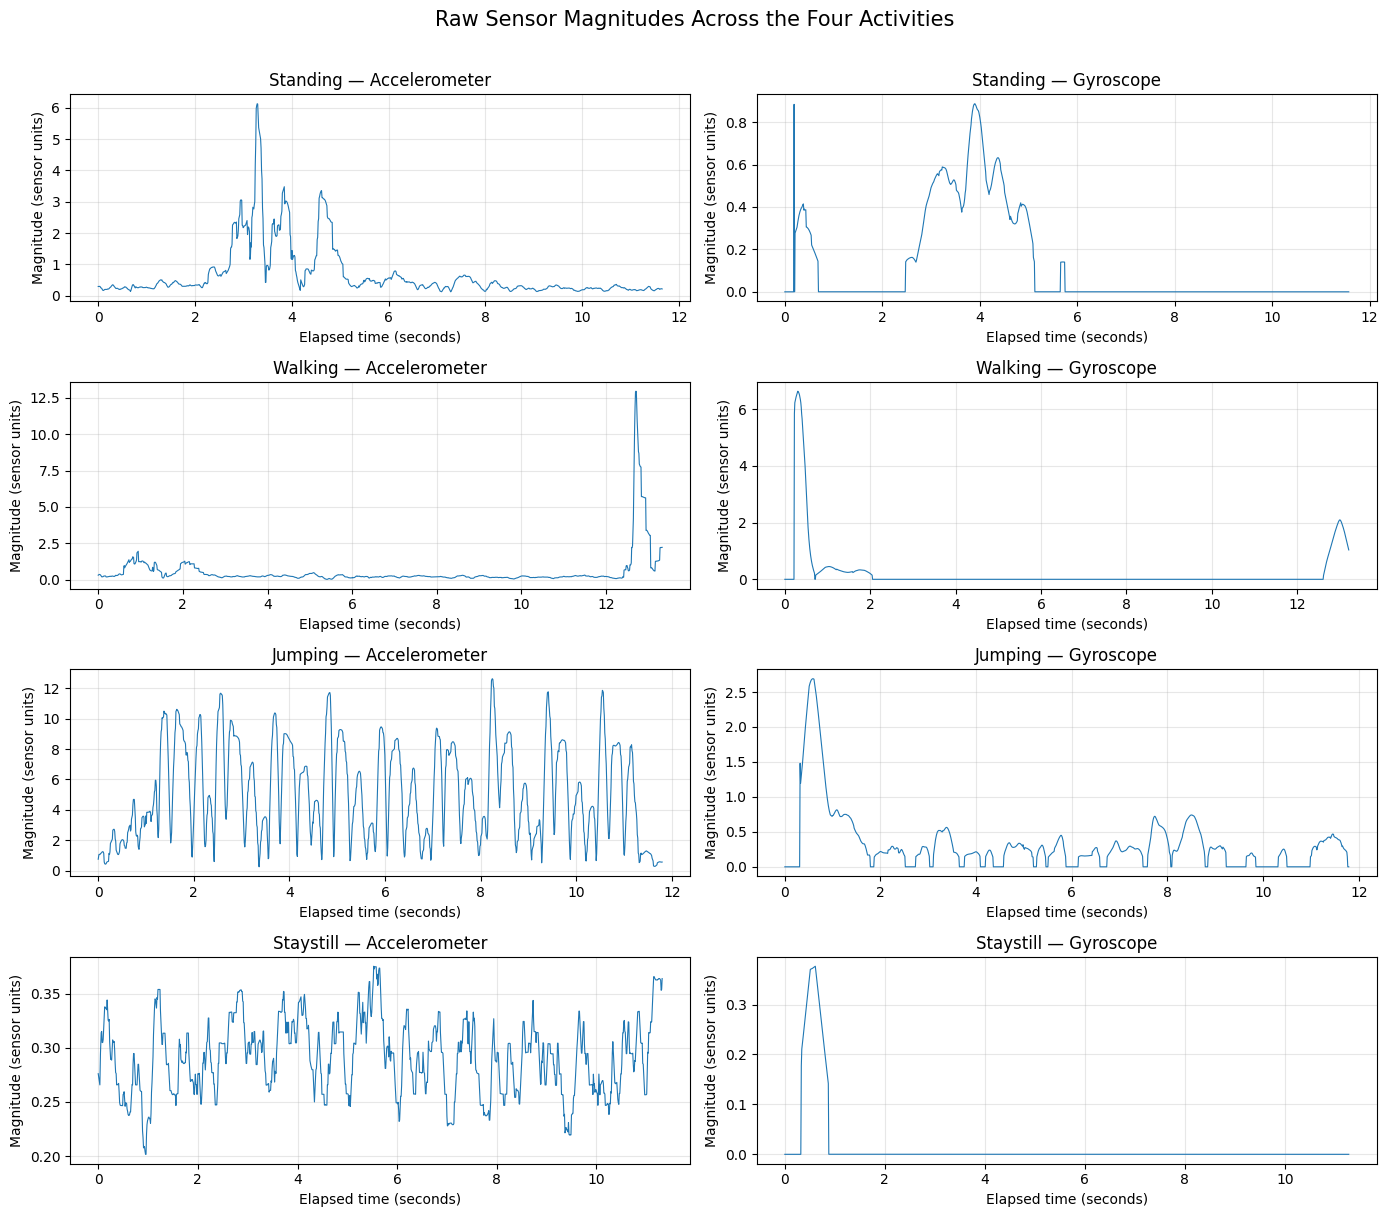

In [12]:
# Plot raw accelerometer and gyroscope magnitudes
# One representative recording per activity; no files are extracted.

import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ACTIVITIES = ["standing", "walking", "jumping", "staystill"]

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(14, 12),
    sharex=False
)

for row_index, activity in enumerate(ACTIVITIES):

    # Choose the first numbered recording for this activity
    activity_rows = inventory_df[
        inventory_df["activity"].str.lower() == activity
    ].copy()

    if activity_rows.empty:
        print(f"No recording found for activity: {activity}")
        continue

    if "recording_number" in activity_rows.columns:
        activity_rows = activity_rows.sort_values("recording_number")

    recording = activity_rows.iloc[0]
    zip_path = Path(recording["path"])

    with zipfile.ZipFile(zip_path, "r") as archive:

        for col_index, sensor_file in enumerate(
            ["Accelerometer.csv", "Gyroscope.csv"]
        ):
            member = find_csv_member(archive, sensor_file)

            if member is None:
                axes[row_index, col_index].set_title(
                    f"{activity}: {sensor_file} not found"
                )
                continue

            with archive.open(member) as file:
                sensor_df = pd.read_csv(file)

            if sensor_df.empty:
                axes[row_index, col_index].set_title(
                    f"{activity}: {sensor_file} is empty"
                )
                continue

            required_columns = [
                "seconds_elapsed", "x", "y", "z"
            ]

            if not all(c in sensor_df.columns for c in required_columns):
                axes[row_index, col_index].set_title(
                    f"{activity}: unexpected column format"
                )
                continue

            # Convert measurements to numeric and remove invalid rows
            for column in required_columns:
                sensor_df[column] = pd.to_numeric(
                    sensor_df[column], errors="coerce"
                )

            sensor_df = sensor_df.dropna(subset=required_columns).copy()

            if sensor_df.empty:
                continue

            # Set elapsed time to start at zero for easier comparison
            time_s = (
                sensor_df["seconds_elapsed"]
                - sensor_df["seconds_elapsed"].iloc[0]
            )

            # Calculate three-axis magnitude
            magnitude = np.sqrt(
                sensor_df["x"] ** 2
                + sensor_df["y"] ** 2
                + sensor_df["z"] ** 2
            )

            ax = axes[row_index, col_index]
            ax.plot(time_s, magnitude, linewidth=0.8)
            ax.set_title(
                f"{activity.title()} — {sensor_file.replace('.csv', '')}"
            )
            ax.set_xlabel("Elapsed time (seconds)")
            ax.set_ylabel("Magnitude (sensor units)")
            ax.grid(True, alpha=0.3)

plt.suptitle(
    "Raw Sensor Magnitudes Across the Four Activities",
    fontsize=15,
    y=1.01
)
plt.tight_layout()
plt.show()

### 7. Windowing and Feature Extraction

Raw sensor measurements are divided into fixed-length windows so that the model can learn from short segments of movement. This project initially uses 2-second windows with a 1-second stride, giving 50% overlap. At approximately 100 Hz, each window is expected to contain about 200 samples per sensor.

For each accelerometer and gyroscope axis, the feature extraction process calculates the mean, standard deviation, variance, and root mean square (RMS). These time-domain features describe the typical sensor value, variability, and signal magnitude.

Additional features are calculated from the three-axis magnitudes: mean and standard deviation describe overall movement, while the dominant non-zero FFT frequency and spectral power provide information about periodic motion and signal energy. Frequency-domain features may help distinguish activities such as walking and jumping from relatively stationary states.

Each feature window retains its activity label and source filename. The windows are created directly from the ZIP archives, without extracting duplicate files to Google Drive.

In [13]:
# Step 10: Window recordings and extract time- and frequency-domain features

import zipfile
import numpy as np
import pandas as pd
from pathlib import Path

# Window configuration
WINDOW_SECONDS = 2.0
STRIDE_SECONDS = 1.0

ACTIVITIES = ["standing", "walking", "jumping", "staystill"]

AXES = ["x", "y", "z"]
SENSORS = ["acc", "gyro"]


def read_sensor_csv(archive, filename):
    """Read a sensor CSV from a ZIP archive and clean its basic columns."""
    member = find_csv_member(archive, filename)

    if member is None:
        return None

    try:
        with archive.open(member) as file:
            df = pd.read_csv(file)
    except pd.errors.EmptyDataError:
        return None

    required = ["seconds_elapsed", "x", "y", "z"]

    if df.empty or not all(c in df.columns for c in required):
        return None

    df = df[required].copy()

    for column in required:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=required)
    df = df.sort_values("seconds_elapsed")
    df = df.drop_duplicates(subset=["seconds_elapsed"])

    return df if not df.empty else None


def extract_axis_features(df, prefix):
    """Extract time-domain features for each sensor axis."""
    features = {}

    for axis in AXES:
        values = df[axis].to_numpy(dtype=float)

        features[f"{prefix}_{axis}_mean"] = float(np.mean(values))
        features[f"{prefix}_{axis}_std"] = float(np.std(values))
        features[f"{prefix}_{axis}_variance"] = float(np.var(values))
        features[f"{prefix}_{axis}_rms"] = float(
            np.sqrt(np.mean(values ** 2))
        )

    return features


def extract_magnitude_features(df, prefix, sampling_rate):
    """Extract magnitude statistics and FFT features."""
    xyz = df[AXES].to_numpy(dtype=float)
    magnitude = np.sqrt(np.sum(xyz ** 2, axis=1))

    features = {
        f"{prefix}_magnitude_mean": float(np.mean(magnitude)),
        f"{prefix}_magnitude_std": float(np.std(magnitude)),
    }

    # Remove the mean to reduce the effect of the DC component.
    centered = magnitude - np.mean(magnitude)

    if len(centered) >= 4 and sampling_rate > 0:
        spectrum = np.abs(np.fft.rfft(centered)) ** 2
        frequencies = np.fft.rfftfreq(
            len(centered),
            d=1.0 / sampling_rate
        )

        # Exclude the zero-frequency component when finding the dominant frequency.
        if len(frequencies) > 1:
            dominant_index = 1 + np.argmax(spectrum[1:])
            dominant_frequency = frequencies[dominant_index]
        else:
            dominant_frequency = 0.0

        spectral_power = float(np.sum(spectrum[1:]) / len(centered))

    else:
        dominant_frequency = 0.0
        spectral_power = 0.0

    features[f"{prefix}_dominant_frequency_hz"] = float(
        dominant_frequency
    )
    features[f"{prefix}_spectral_power"] = spectral_power

    return features


def estimate_sampling_rate(df):
    """Estimate the sampling rate from positive timestamp differences."""
    times = df["seconds_elapsed"].to_numpy(dtype=float)
    differences = np.diff(times)
    positive_differences = differences[differences > 0]

    if len(positive_differences) == 0:
        return np.nan

    return float(1.0 / np.median(positive_differences))


feature_rows = []
skipped_recordings = []

for _, recording in inventory_df.iterrows():
    zip_path = Path(recording["path"])
    activity = str(recording["activity"]).lower()

    try:
        with zipfile.ZipFile(zip_path, "r") as archive:
            acc_df = read_sensor_csv(archive, "Accelerometer.csv")
            gyro_df = read_sensor_csv(archive, "Gyroscope.csv")

    except (zipfile.BadZipFile, OSError) as error:
        skipped_recordings.append({
            "filename": zip_path.name,
            "reason": f"Could not read ZIP: {error}"
        })
        continue

    if acc_df is None or gyro_df is None:
        skipped_recordings.append({
            "filename": zip_path.name,
            "reason": "Missing or unusable accelerometer/gyroscope data"
        })
        continue

    # Use a common time range covered by both sensors.
    common_start = max(
        acc_df["seconds_elapsed"].min(),
        gyro_df["seconds_elapsed"].min()
    )
    common_end = min(
        acc_df["seconds_elapsed"].max(),
        gyro_df["seconds_elapsed"].max()
    )

    if common_end - common_start < WINDOW_SECONDS:
        skipped_recordings.append({
            "filename": zip_path.name,
            "reason": "Insufficient overlapping sensor duration"
        })
        continue

    acc_rate = estimate_sampling_rate(acc_df)
    gyro_rate = estimate_sampling_rate(gyro_df)

    window_number = 0
    window_start = common_start

    while window_start + WINDOW_SECONDS <= common_end + 1e-9:
        window_end = window_start + WINDOW_SECONDS

        # The same time boundaries are applied to both sensors.
        acc_window = acc_df[
            (acc_df["seconds_elapsed"] >= window_start)
            & (acc_df["seconds_elapsed"] < window_end)
        ]

        gyro_window = gyro_df[
            (gyro_df["seconds_elapsed"] >= window_start)
            & (gyro_df["seconds_elapsed"] < window_end)
        ]

        # Skip windows with too few observations to characterize reliably.
        if len(acc_window) >= 100 and len(gyro_window) >= 100:
            features = {}

            features.update(
                extract_axis_features(acc_window, "acc")
            )
            features.update(
                extract_axis_features(gyro_window, "gyro")
            )

            features.update(
                extract_magnitude_features(
                    acc_window, "acc", acc_rate
                )
            )
            features.update(
                extract_magnitude_features(
                    gyro_window, "gyro", gyro_rate
                )
            )

            features.update({
                "filename": zip_path.name,
                "activity": activity,
                "window_number": window_number,
                "window_start_s": float(window_start - common_start),
                "window_end_s": float(window_end - common_start),
                "acc_samples": len(acc_window),
                "gyro_samples": len(gyro_window),
                "acc_sampling_hz": acc_rate,
                "gyro_sampling_hz": gyro_rate,
            })

            feature_rows.append(features)
            window_number += 1

        window_start += STRIDE_SECONDS

    if window_number == 0:
        skipped_recordings.append({
            "filename": zip_path.name,
            "reason": "No windows passed the sample-count checks"
        })


features_df = pd.DataFrame(feature_rows)

print("Feature extraction complete.")
print("Recordings in inventory:", len(inventory_df))
print("Recordings contributing windows:",
      features_df["filename"].nunique() if not features_df.empty else 0)
print("Total windows created:", len(features_df))

print("\nWindows per activity:")
if not features_df.empty:
    display(
        features_df["activity"]
        .value_counts()
        .reindex(ACTIVITIES, fill_value=0)
        .rename("windows")
        .to_frame()
    )

print("\nFeature table shape:", features_df.shape)

metadata_columns = [
    "filename", "activity", "window_number",
    "window_start_s", "window_end_s",
    "acc_samples", "gyro_samples"
]

print("\nExample window metadata:")
display(features_df[metadata_columns].head())

feature_columns = [
    column for column in features_df.columns
    if column.startswith(("acc_", "gyro_"))
    and column not in ["acc_samples", "gyro_samples",
                       "acc_sampling_hz", "gyro_sampling_hz"]
]

print("\nNumber of extracted features:", len(feature_columns))
print("Feature names:")
print(feature_columns)

print("\nRecordings skipped:", len(skipped_recordings))
if skipped_recordings:
    display(pd.DataFrame(skipped_recordings).head(20))

Feature extraction complete.
Recordings in inventory: 200
Recordings contributing windows: 200
Total windows created: 1925

Windows per activity:


,windows
activity,
standing,487
walking,475
jumping,477
staystill,486



Feature table shape: (1925, 41)

Example window metadata:


,filename,activity,window_number,window_start_s,window_end_s,acc_samples,gyro_samples
0,jumping_01.zip,jumping,0,0.0,2.0,200,200
1,jumping_01.zip,jumping,1,1.0,3.0,200,200
2,jumping_01.zip,jumping,2,2.0,4.0,200,200
3,jumping_01.zip,jumping,3,3.0,5.0,200,200
4,jumping_01.zip,jumping,4,4.0,6.0,200,200



Number of extracted features: 32
Feature names:
['acc_x_mean', 'acc_x_std', 'acc_x_variance', 'acc_x_rms', 'acc_y_mean', 'acc_y_std', 'acc_y_variance', 'acc_y_rms', 'acc_z_mean', 'acc_z_std', 'acc_z_variance', 'acc_z_rms', 'gyro_x_mean', 'gyro_x_std', 'gyro_x_variance', 'gyro_x_rms', 'gyro_y_mean', 'gyro_y_std', 'gyro_y_variance', 'gyro_y_rms', 'gyro_z_mean', 'gyro_z_std', 'gyro_z_variance', 'gyro_z_rms', 'acc_magnitude_mean', 'acc_magnitude_std', 'acc_dominant_frequency_hz', 'acc_spectral_power', 'gyro_magnitude_mean', 'gyro_magnitude_std', 'gyro_dominant_frequency_hz', 'gyro_spectral_power']

Recordings skipped: 0


### 8. Recording-Level Train/Test Split and Feature Normalization

The dataset contains overlapping windows, so randomly splitting individual windows could place nearly identical segments from the same recording in both training and testing data. This would lead to an overly optimistic evaluation.

To avoid this, the split is performed at the original recording level. Two recordings from each activity are reserved as unseen test data, giving eight test recordings in total. The remaining recordings are used for training.

Twenty features are selected from the original 32 candidate features. These include axis means and standard deviations, magnitude statistics, dominant FFT frequency, and spectral power for both sensors. Redundant variance features are excluded because they contain the same information as standard deviation.

Z-score normalization is then fitted using training windows only. The fitted transformation is applied to both training and test windows, preventing information from the test set from influencing the normalization parameters.

In [14]:
# Step 11: Split by original recording and normalize selected features

from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Set a reproducible split
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

ACTIVITIES = ["standing", "walking", "jumping", "staystill"]

# Select 20 features: axis means/stds and magnitude/FFT features.
selected_features = []

for sensor in ["acc", "gyro"]:
    for axis in ["x", "y", "z"]:
        selected_features.extend([
            f"{sensor}_{axis}_mean",
            f"{sensor}_{axis}_std"
        ])

    selected_features.extend([
        f"{sensor}_magnitude_mean",
        f"{sensor}_magnitude_std",
        f"{sensor}_dominant_frequency_hz",
        f"{sensor}_spectral_power"
    ])

print("Selected feature count:", len(selected_features))
print("Selected features:")
for feature in selected_features:
    print("-", feature)

# Confirm all selected features are available
missing_features = [
    feature for feature in selected_features
    if feature not in features_df.columns
]

if missing_features:
    raise ValueError(
        f"Selected features are missing: {missing_features}"
    )

# Make a recording-level label table
recording_labels = (
    features_df[["filename", "activity"]]
    .drop_duplicates()
    .sort_values(["activity", "filename"])
    .reset_index(drop=True)
)

# Select exactly two unseen recordings from each activity.
test_filenames = []

for activity in ACTIVITIES:
    candidates = recording_labels.loc[
        recording_labels["activity"] == activity, "filename"
    ].to_numpy()

    if len(candidates) < 3:
        raise ValueError(
            f"Not enough recordings for activity '{activity}'."
        )

    chosen = rng.choice(candidates, size=2, replace=False)
    test_filenames.extend(chosen.tolist())

# Assign all windows from a recording to the same partition.
is_test = features_df["filename"].isin(test_filenames)

train_df = features_df.loc[~is_test].copy().reset_index(drop=True)
test_df = features_df.loc[is_test].copy().reset_index(drop=True)

# Check that no recording appears in both partitions.
train_recordings = set(train_df["filename"])
test_recordings = set(test_df["filename"])

assert train_recordings.isdisjoint(test_recordings), (
    "Data leakage detected: a recording appears in both sets."
)

# Check all four classes are present in both sets.
print("\nTraining recordings per activity:")
display(
    train_df[["filename", "activity"]]
    .drop_duplicates()["activity"]
    .value_counts()
    .reindex(ACTIVITIES, fill_value=0)
    .rename("training_recordings")
    .to_frame()
)

print("\nHeld-out test recordings:")
display(
    test_df[["filename", "activity"]]
    .drop_duplicates()
    .sort_values(["activity", "filename"])
    .reset_index(drop=True)
)

print("\nTraining windows:", len(train_df))
print("Test windows:", len(test_df))
print("Training recordings:", len(train_recordings))
print("Test recordings:", len(test_recordings))

# Replace infinite values and check selected feature values.
X_train_raw = train_df[selected_features].replace(
    [np.inf, -np.inf], np.nan
)
X_test_raw = test_df[selected_features].replace(
    [np.inf, -np.inf], np.nan
)

if X_train_raw.isna().any().any() or X_test_raw.isna().any().any():
    raise ValueError(
        "Missing or infinite feature values found. "
        "We must resolve these before fitting the scaler."
    )

# Fit normalization only on training data.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print("\nNormalization complete.")
print("Training feature matrix:", X_train.shape)
print("Test feature matrix:", X_test.shape)
print("Training feature means (first 5):",
      np.round(X_train.mean(axis=0)[:5], 3))
print("Training feature standard deviations (first 5):",
      np.round(X_train.std(axis=0)[:5], 3))

Selected feature count: 20
Selected features:
- acc_x_mean
- acc_x_std
- acc_y_mean
- acc_y_std
- acc_z_mean
- acc_z_std
- acc_magnitude_mean
- acc_magnitude_std
- acc_dominant_frequency_hz
- acc_spectral_power
- gyro_x_mean
- gyro_x_std
- gyro_y_mean
- gyro_y_std
- gyro_z_mean
- gyro_z_std
- gyro_magnitude_mean
- gyro_magnitude_std
- gyro_dominant_frequency_hz
- gyro_spectral_power

Training recordings per activity:


,training_recordings
activity,
standing,48
walking,48
jumping,48
staystill,48



Held-out test recordings:


,filename,activity
0,jumping_013.zip,jumping
1,jumping_040.zip,jumping
2,standing_013.zip,standing
3,standing_044.zip,standing
4,staystill_013.zip,staystill
5,staystill_033.zip,staystill
6,walking_029.zip,walking
7,walking_09.zip,walking



Training windows: 1848
Test windows: 77
Training recordings: 192
Test recordings: 8

Normalization complete.
Training feature matrix: (1848, 20)
Test feature matrix: (77, 20)
Training feature means (first 5): [ 0. -0.  0. -0. -0.]
Training feature standard deviations (first 5): [1. 1. 1. 1. 1.]


### 9. Gaussian Hidden Markov Model Implementation

A Hidden Markov Model represents observed data as the output of a sequence of hidden states. In this project, the observations are the 20 normalized sensor features extracted from successive windows.

Four separate Gaussian HMMs are trained, one for each activity: standing, walking, jumping, and staystill. Each model has three hidden states. The hidden states represent recurring sensor patterns learned from the training data; they are not assumed to correspond to specific physical movements in advance.

The models use diagonal Gaussian emission distributions, which estimate a mean and variance for each feature in each hidden state. This approach captures continuous-valued sensor features while keeping the parameter estimation manageable.

Baum–Welch, an Expectation-Maximization algorithm, estimates the initial-state probabilities, transition probabilities, and emission parameters. The forward-backward algorithm calculates the expected hidden-state probabilities, and the parameters are updated iteratively. Training stops when the improvement in log-likelihood becomes sufficiently small or the maximum number of iterations is reached.

All training sequences are grouped by their original recording, preserving the temporal order of the windows. The held-out recordings remain unused during model fitting.

In [16]:
# Step 12 (optimized): Train four Gaussian HMMs using Baum-Welch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.special import logsumexp
from sklearn.cluster import KMeans

ACTIVITIES = ["standing", "walking", "jumping", "staystill"]

N_STATES = 3
MAX_ITERATIONS = 20
CONVERGENCE_TOLERANCE = 1e-2
VARIANCE_FLOOR = 1e-3
RANDOM_SEED = 42


def gaussian_log_emissions(X, means, variances):
    """Log probabilities of observations under diagonal Gaussian emissions."""
    differences = X[:, None, :] - means[None, :, :]

    return -0.5 * np.sum(
        np.log(2.0 * np.pi * variances)[None, :, :]
        + differences**2 / variances[None, :, :],
        axis=2
    )


def forward_backward(log_emissions, initial_probs, transition_probs):
    """Calculate log-likelihood, state posteriors, and expected transitions."""
    T, K = log_emissions.shape

    log_initial = np.log(np.maximum(initial_probs, 1e-300))
    log_transition = np.log(np.maximum(transition_probs, 1e-300))

    # Forward probabilities
    alpha = np.empty((T, K))
    alpha[0] = log_initial + log_emissions[0]

    for t in range(1, T):
        alpha[t] = log_emissions[t] + logsumexp(
            alpha[t - 1][:, None] + log_transition,
            axis=0
        )

    log_likelihood = float(logsumexp(alpha[-1]))

    # Backward probabilities
    beta = np.zeros((T, K))

    for t in range(T - 2, -1, -1):
        beta[t] = logsumexp(
            log_transition
            + log_emissions[t + 1][None, :]
            + beta[t + 1][None, :],
            axis=1
        )

    # Posterior probability of each hidden state
    gamma = np.exp(
        alpha + beta - log_likelihood
    )

    # Expected transition counts, calculated in a vectorized time operation
    if T > 1:
        log_xi = (
            alpha[:-1, :, None]
            + log_transition[None, :, :]
            + log_emissions[1:, None, :]
            + beta[1:, None, :]
            - log_likelihood
        )

        xi_sum = np.exp(log_xi).sum(axis=0)
    else:
        xi_sum = np.zeros((K, K))

    return log_likelihood, gamma, xi_sum


def initialize_hmm(sequences, n_states, seed):
    """Initialize Gaussian emissions using K-means."""
    observations = np.vstack(sequences)

    kmeans = KMeans(
        n_clusters=n_states,
        n_init=5,
        random_state=seed
    )
    labels = kmeans.fit_predict(observations)

    means = kmeans.cluster_centers_
    global_variance = np.var(observations, axis=0) + VARIANCE_FLOOR

    variances = np.empty_like(means)

    for state in range(n_states):
        cluster = observations[labels == state]

        if len(cluster) >= 2:
            variances[state] = np.var(cluster, axis=0)
        else:
            variances[state] = global_variance

    variances = np.maximum(variances, VARIANCE_FLOOR)

    transition_probs = np.full((n_states, n_states), 0.2 / (n_states - 1))
    np.fill_diagonal(transition_probs, 0.8)

    initial_probs = np.full(n_states, 1.0 / n_states)

    return initial_probs, transition_probs, means, variances


def fit_gaussian_hmm(
    sequences,
    n_states=3,
    max_iterations=20,
    tolerance=1e-2,
    seed=42
):
    """Fit a diagonal Gaussian HMM using Baum-Welch."""
    initial_probs, transition_probs, means, variances = initialize_hmm(
        sequences, n_states, seed
    )

    likelihood_history = []

    for iteration in range(max_iterations):
        initial_counts = np.zeros(n_states)
        transition_counts = np.zeros((n_states, n_states))
        state_weights = np.zeros(n_states)
        weighted_sum = np.zeros_like(means)
        weighted_square_sum = np.zeros_like(variances)

        total_log_likelihood = 0.0

        # Each recording is processed separately to preserve sequence boundaries.
        for sequence in sequences:
            emissions = gaussian_log_emissions(
                sequence, means, variances
            )

            likelihood, gamma, xi_sum = forward_backward(
                emissions, initial_probs, transition_probs
            )

            total_log_likelihood += likelihood
            initial_counts += gamma[0]
            transition_counts += xi_sum
            state_weights += gamma.sum(axis=0)
            weighted_sum += gamma.T @ sequence
            weighted_square_sum += gamma.T @ (sequence**2)

        likelihood_history.append(total_log_likelihood)

        # M-step: update initial and transition probabilities.
        initial_probs = initial_counts + 1e-6
        initial_probs /= initial_probs.sum()

        transition_counts += 1e-6
        transition_probs = transition_counts / (
            transition_counts.sum(axis=1, keepdims=True)
        )

        # M-step: update Gaussian means and variances.
        safe_weights = np.maximum(state_weights, 1e-8)
        means = weighted_sum / safe_weights[:, None]

        variances = (
            weighted_square_sum / safe_weights[:, None] - means**2
        )
        variances = np.maximum(variances, VARIANCE_FLOOR)

        # Report progress so it is clear that training is moving.
        if iteration == 0 or (iteration + 1) % 5 == 0:
            print(
                f"  Iteration {iteration + 1}/{max_iterations}: "
                f"log-likelihood = {total_log_likelihood:.2f}"
            )

        if len(likelihood_history) >= 2:
            improvement = (
                likelihood_history[-1] - likelihood_history[-2]
            )

            if abs(improvement) < tolerance:
                break

    converged = (
        len(likelihood_history) >= 2
        and abs(likelihood_history[-1] - likelihood_history[-2]) < tolerance
    )

    return {
        "initial_probs": initial_probs,
        "transition_probs": transition_probs,
        "means": means,
        "variances": variances,
        "log_likelihood_history": likelihood_history,
        "iterations": len(likelihood_history),
        "converged": converged
    }


# Prepare normalized training sequences.
# Pass DataFrames to the scaler to avoid feature-name warnings.
train_sequences = {}

for filename, group in train_df.groupby("filename"):
    group = group.sort_values("window_number")
    train_sequences[filename] = scaler.transform(
        group[selected_features]
    )


# Train one HMM for each activity.
hmm_models = {}
training_results = []

for activity_index, activity in enumerate(ACTIVITIES):
    filenames = (
        train_df.loc[train_df["activity"] == activity, "filename"]
        .drop_duplicates()
        .tolist()
    )

    sequences = [train_sequences[name] for name in filenames]

    print(f"\nTraining HMM for: {activity}")

    model = fit_gaussian_hmm(
        sequences,
        n_states=N_STATES,
        max_iterations=MAX_ITERATIONS,
        tolerance=CONVERGENCE_TOLERANCE,
        seed=RANDOM_SEED + activity_index
    )

    hmm_models[activity] = model

    training_results.append({
        "activity": activity,
        "training_recordings": len(sequences),
        "hidden_states": N_STATES,
        "iterations": model["iterations"],
        "final_log_likelihood": model["log_likelihood_history"][-1],
        "converged": model["converged"]
    })

    print("Converged:", model["converged"])


training_results_df = pd.DataFrame(training_results)

print("\nHMM training summary:")
display(training_results_df)


Training HMM for: standing
  Iteration 1/20: log-likelihood = 3438.42
  Iteration 5/20: log-likelihood = 4835.49
  Iteration 10/20: log-likelihood = 5433.01
  Iteration 15/20: log-likelihood = 5596.31
  Iteration 20/20: log-likelihood = 5604.33
Converged: False

Training HMM for: walking
  Iteration 1/20: log-likelihood = -4080.29
  Iteration 5/20: log-likelihood = -3581.18
  Iteration 10/20: log-likelihood = -3500.01
  Iteration 15/20: log-likelihood = -3441.19
  Iteration 20/20: log-likelihood = -3436.48
Converged: False

Training HMM for: jumping
  Iteration 1/20: log-likelihood = -9033.72
Converged: True

Training HMM for: staystill
  Iteration 1/20: log-likelihood = 18891.36
  Iteration 5/20: log-likelihood = 20479.90
  Iteration 10/20: log-likelihood = 20719.30
Converged: True

HMM training summary:


,activity,training_recordings,hidden_states,iterations,final_log_likelihood,converged
0,standing,48,3,20,5604.333297,False
1,walking,48,3,20,-3436.483194,False
2,jumping,48,3,3,-8661.529828,True
3,staystill,48,3,11,20719.308119,True


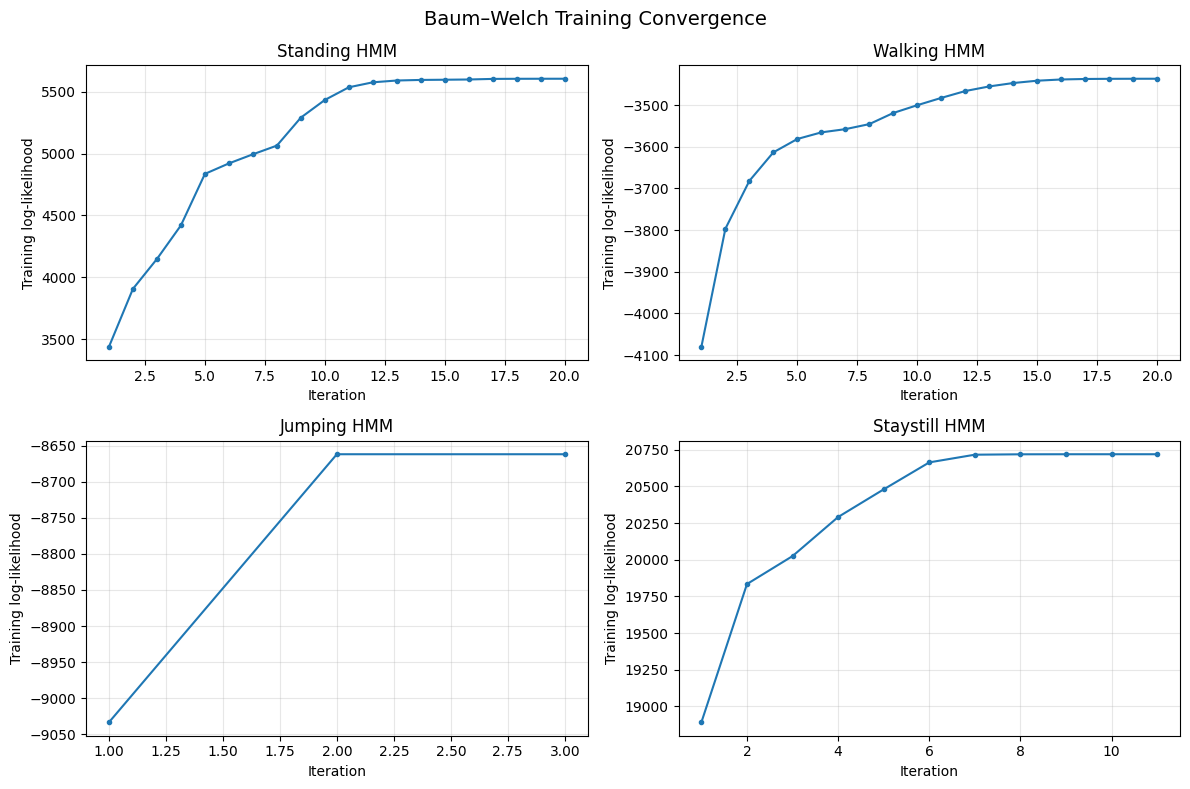

In [17]:
# Plot Baum-Welch log-likelihood histories

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8)
)

for ax, activity in zip(axes.ravel(), ACTIVITIES):
    history = hmm_models[activity]["log_likelihood_history"]

    ax.plot(
        range(1, len(history) + 1),
        history,
        marker="o",
        markersize=3
    )

    ax.set_title(f"{activity.title()} HMM")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Training log-likelihood")
    ax.grid(True, alpha=0.3)

plt.suptitle("Baum–Welch Training Convergence", fontsize=14)
plt.tight_layout()
plt.show()

##10 Viterbi decoding and activity prediction
The Viterbi algorithm identifies the most likely sequence of hidden states for a given observation sequence. For activity classification, each unseen recording is evaluated under all four trained HMMs. I'll select the activity model with the highest average log-likelihood per observation, which makes comparisons less sensitive to recording length. The test recordings were held out before training and are used only for evaluation. Viterbi decoding is also applied to show the hidden-state sequence inferred by each model.

In [18]:

# Step 14: Viterbi decoding and prediction on unseen recordings

def viterbi_decode(X, model):
    """Return the most likely hidden-state path for a sequence."""
    log_emissions = gaussian_log_emissions(
        X, model["means"], model["variances"]
    )

    initial = np.log(np.maximum(model["initial_probs"], 1e-300))
    transition = np.log(
        np.maximum(model["transition_probs"], 1e-300)
    )

    T, n_states = log_emissions.shape
    scores = np.empty((T, n_states))
    backpointers = np.zeros((T, n_states), dtype=int)

    scores[0] = initial + log_emissions[0]

    for t in range(1, T):
        candidates = scores[t - 1][:, None] + transition
        backpointers[t] = np.argmax(candidates, axis=0)
        scores[t] = (
            np.max(candidates, axis=0) + log_emissions[t]
        )

    path = np.zeros(T, dtype=int)
    path[-1] = np.argmax(scores[-1])

    for t in range(T - 2, -1, -1):
        path[t] = backpointers[t + 1, path[t + 1]]

    return path, float(np.max(scores[-1]))


def score_sequence(X, model):
    """Calculate average log-likelihood per observation."""
    log_emissions = gaussian_log_emissions(
        X, model["means"], model["variances"]
    )

    initial = np.log(np.maximum(model["initial_probs"], 1e-300))
    transition = np.log(
        np.maximum(model["transition_probs"], 1e-300)
    )

    alpha = initial + log_emissions[0]

    for t in range(1, len(X)):
        alpha = log_emissions[t] + logsumexp(
            alpha[:, None] + transition, axis=0
        )

    total_log_likelihood = float(logsumexp(alpha))
    return total_log_likelihood / len(X)


# Prepare each held-out recording using the training-fitted scaler.
test_sequences = {}

for filename, group in test_df.groupby("filename"):
    group = group.sort_values("window_number")
    X_test = scaler.transform(group[selected_features])
    test_sequences[filename] = {
        "activity": group["activity"].iloc[0],
        "X": X_test
    }


# Compare each unseen recording against all four activity models.
prediction_rows = []
viterbi_examples = {}

for filename, item in test_sequences.items():
    X_test = item["X"]
    true_activity = item["activity"]

    scores = {
        activity: score_sequence(X_test, hmm_models[activity])
        for activity in ACTIVITIES
    }

    predicted_activity = max(scores, key=scores.get)

    # Decode the most likely hidden-state sequence under the winning model.
    best_path, best_path_score = viterbi_decode(
        X_test, hmm_models[predicted_activity]
    )

    viterbi_examples[filename] = {
        "predicted_activity": predicted_activity,
        "hidden_states": best_path
    }

    row = {
        "filename": filename,
        "actual_activity": true_activity,
        "predicted_activity": predicted_activity,
        "windows": len(X_test),
        "viterbi_final_score": best_path_score
    }

    for activity, score in scores.items():
        row[f"score_{activity}"] = score

    prediction_rows.append(row)


predictions_df = pd.DataFrame(prediction_rows)

print("Held-out recording predictions:")
display(
    predictions_df[
        ["filename", "actual_activity", "predicted_activity", "windows"]
    ].sort_values(["actual_activity", "filename"])
)

print("\nNumber of test recordings:", len(predictions_df))


Held-out recording predictions:


,filename,actual_activity,predicted_activity,windows
0,jumping_013.zip,jumping,jumping,10
1,jumping_040.zip,jumping,jumping,9
2,standing_013.zip,standing,walking,10
3,standing_044.zip,standing,standing,10
4,staystill_013.zip,staystill,staystill,9
5,staystill_033.zip,staystill,staystill,10
6,walking_029.zip,walking,walking,10
7,walking_09.zip,walking,standing,9



Number of test recordings: 8


##11 Confusion matrix and evaluation metrics

The confusion matrix compares the actual activity labels with the activities predicted by the HMM. Accuracy measures the proportion of all recordings classified correctly. Sensitivity measures how often recordings of a particular activity are correctly identified, while specificity measures how often recordings from the other activities are correctly rejected. These metrics help me identify which activities the model recognizes well and which activities it confuses. Since the test set contains only eight recordings, the results should be interpreted cautiously.

Recording-level accuracy: 75.00%

Sensitivity and specificity by activity:


,activity,sensitivity,specificity
0,standing,50.00%,83.33%
1,walking,50.00%,83.33%
2,jumping,100.00%,100.00%
3,staystill,100.00%,100.00%


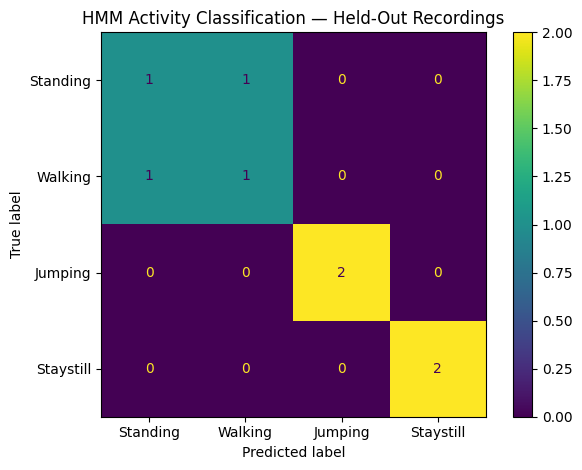


Classification report:
              precision    recall  f1-score   support

    standing       0.50      0.50      0.50         2
     walking       0.50      0.50      0.50         2
     jumping       1.00      1.00      1.00         2
   staystill       1.00      1.00      1.00         2

    accuracy                           0.75         8
   macro avg       0.75      0.75      0.75         8
weighted avg       0.75      0.75      0.75         8



In [19]:

# Step 15: Evaluate the HMM on held-out recordings

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use a consistent activity order throughout the evaluation.
y_true = predictions_df["actual_activity"]
y_pred = predictions_df["predicted_activity"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=ACTIVITIES
)

# Overall accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"Recording-level accuracy: {accuracy:.2%}")

# Per-activity sensitivity and specificity
metric_rows = []

for i, activity in enumerate(ACTIVITIES):
    true_positive = cm[i, i]
    false_negative = cm[i, :].sum() - true_positive
    false_positive = cm[:, i].sum() - true_positive
    true_negative = cm.sum() - (
        true_positive + false_negative + false_positive
    )

    sensitivity = (
        true_positive / (true_positive + false_negative)
        if (true_positive + false_negative) > 0 else 0
    )

    specificity = (
        true_negative / (true_negative + false_positive)
        if (true_negative + false_positive) > 0 else 0
    )

    metric_rows.append({
        "activity": activity,
        "sensitivity": sensitivity,
        "specificity": specificity
    })

metrics_df = pd.DataFrame(metric_rows)

print("\nSensitivity and specificity by activity:")
display(
    metrics_df.style.format({
        "sensitivity": "{:.2%}",
        "specificity": "{:.2%}"
    })
)

# Display the confusion matrix.
display_labels = [activity.title() for activity in ACTIVITIES]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(values_format="d")
plt.title("HMM Activity Classification — Held-Out Recordings")
plt.tight_layout()
plt.show()

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=ACTIVITIES,
        zero_division=0
    )
)


## 12 Visualize transition and emission parameters

The HMM has two important sets of learned parameters. The transition matrix describes the probability of moving from one hidden state to another between consecutive observation windows. The Gaussian emission parameters describe the sensor-feature patterns associated with each hidden state. Because this model uses continuous observations and Gaussian emissions, the emission visualization below shows learned feature means rather than categorical emission probabilities. The features were standardized using the training data, so the means are expressed in standardized units.

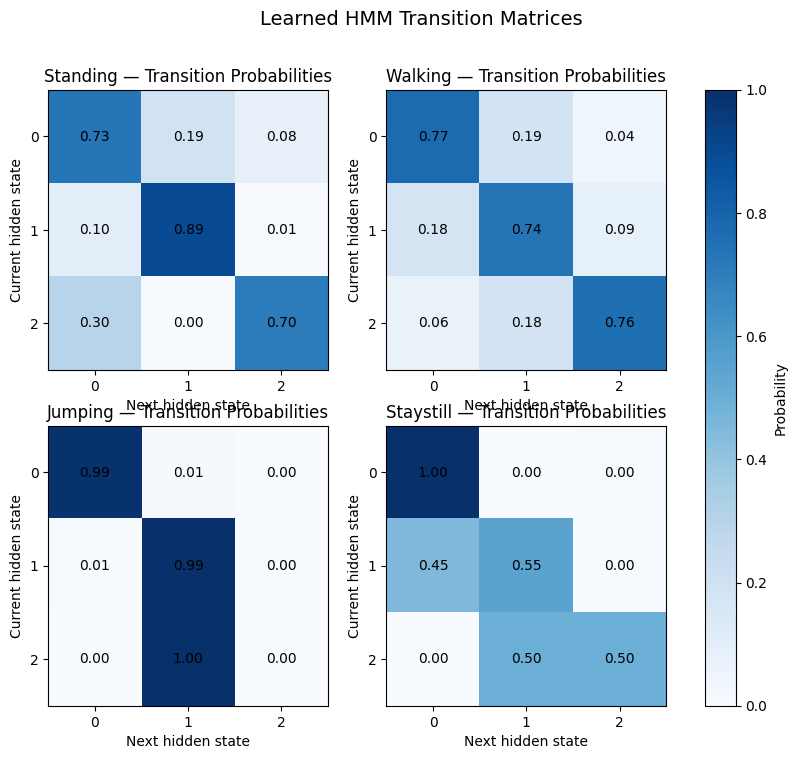

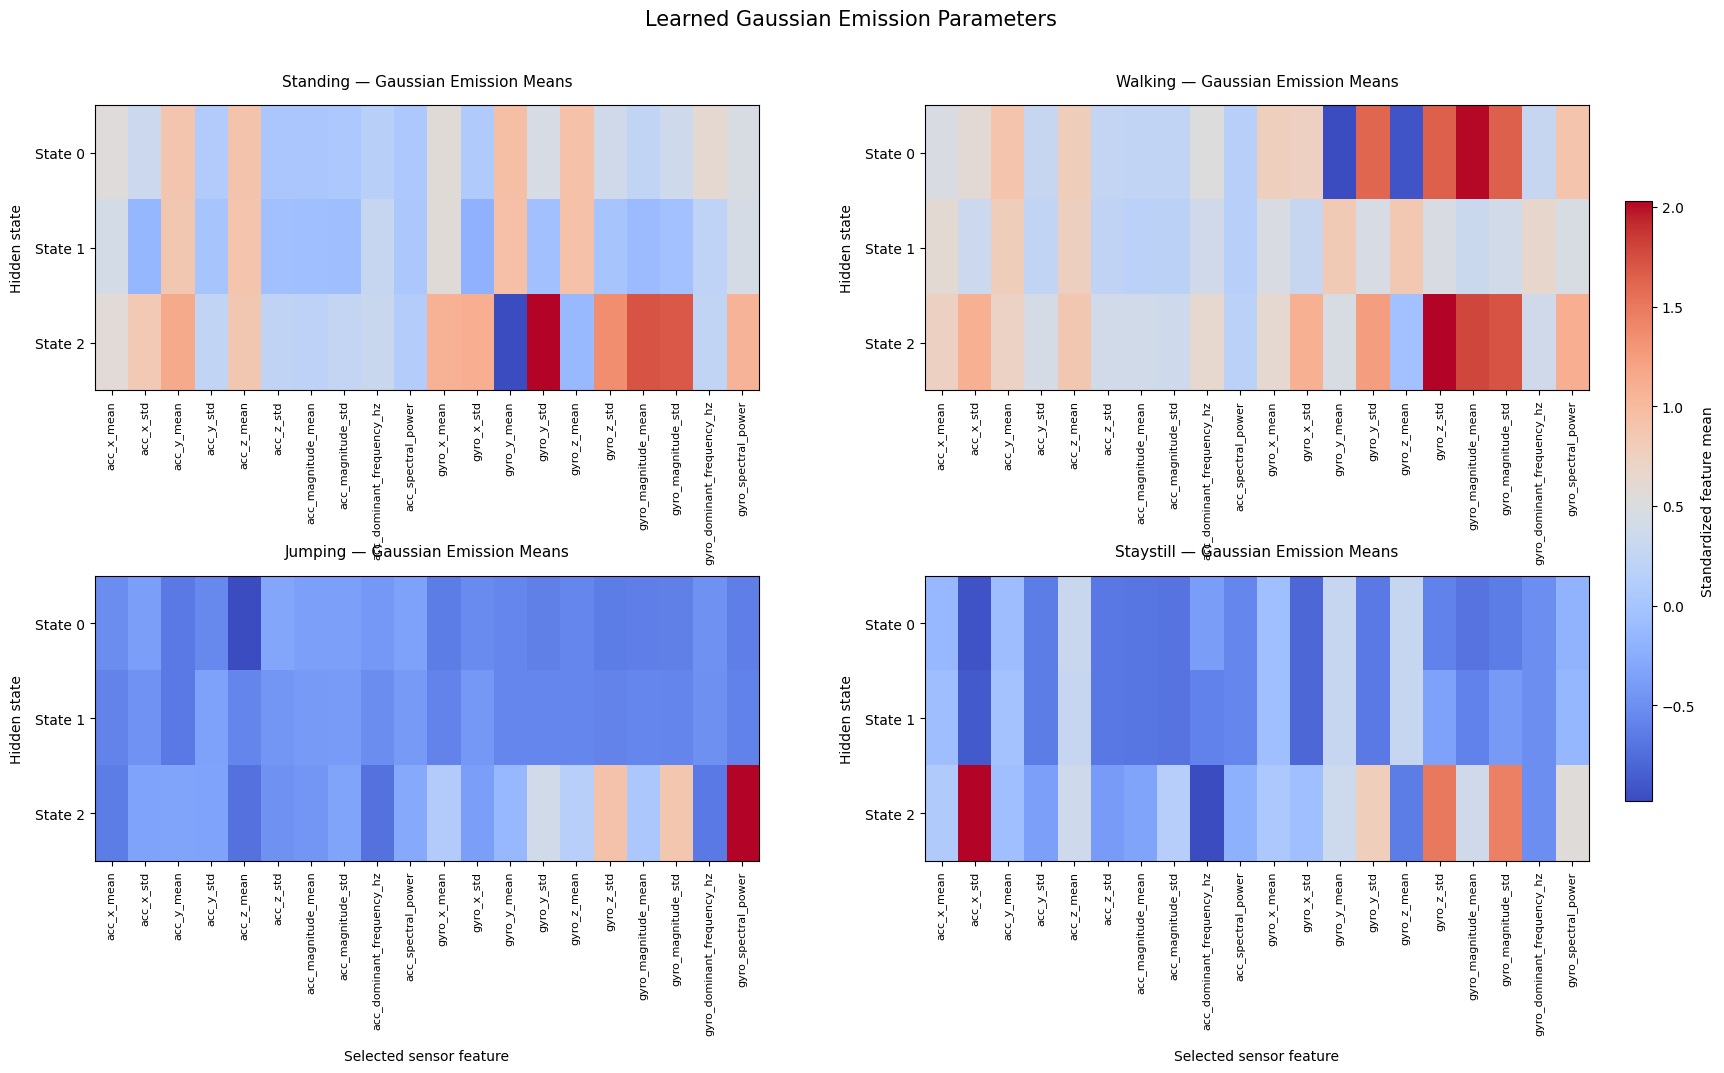

In [21]:

# Step 16: Visualize HMM transition matrices and Gaussian emission means

import numpy as np
import matplotlib.pyplot as plt

# 1. Transition probability matrices: one heatmap per activity.
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, activity in zip(axes.ravel(), ACTIVITIES):
    transition_matrix = hmm_models[activity]["transition_probs"]

    image = ax.imshow(
        transition_matrix,
        vmin=0,
        vmax=1,
        cmap="Blues"
    )

    ax.set_title(f"{activity.title()} — Transition Probabilities")
    ax.set_xlabel("Next hidden state")
    ax.set_ylabel("Current hidden state")
    ax.set_xticks(range(N_STATES))
    ax.set_yticks(range(N_STATES))

    for i in range(N_STATES):
        for j in range(N_STATES):
            ax.text(
                j, i, f"{transition_matrix[i, j]:.2f}",
                ha="center", va="center"
            )

fig.colorbar(image, ax=axes.ravel().tolist(), label="Probability")
fig.suptitle("Learned HMM Transition Matrices", fontsize=14)
plt.show()


# 2. Gaussian emission means: one heatmap per activity.

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12)
)

# Add more vertical and horizontal space between plots.
fig.subplots_adjust(
    left=0.08,
    right=0.91,
    bottom=0.25,
    top=0.88,
    hspace=0.65,
    wspace=0.25
)

for ax, activity in zip(axes.ravel(), ACTIVITIES):
    emission_means = hmm_models[activity]["means"]

    image = ax.imshow(
        emission_means,
        aspect="auto",
        cmap="coolwarm"
    )

    # Keep each subplot title separate and readable.
    ax.set_title(
        f"{activity.title()} — Gaussian Emission Means",
        fontsize=11,
        pad=14
    )

    ax.set_xlabel("Selected sensor feature", labelpad=10)
    ax.set_ylabel("Hidden state", labelpad=8)

    ax.set_yticks(range(N_STATES))
    ax.set_yticklabels([f"State {i}" for i in range(N_STATES)])

    ax.set_xticks(range(len(selected_features)))
    ax.set_xticklabels(
        selected_features,
        rotation=90,
        fontsize=8
    )

# Keep the shared color scale outside the plots.
colorbar_ax = fig.add_axes([0.93, 0.30, 0.015, 0.50])
fig.colorbar(
    image,
    cax=colorbar_ax,
    label="Standardized feature mean"
)

fig.suptitle(
    "Learned Gaussian Emission Parameters",
    fontsize=15,
    y=0.96
)

plt.show()

## 13 Summarize my experiment

In this section, Isummarized the dataset, training setup, and held-out evaluation results. The summary connects the technical implementation to the project objective of recognizing four human activity states from accelerometer and gyroscope measurements.

In [22]:

# Step 17: Final experiment summary

print("=" * 55)
print("HMM HUMAN ACTIVITY RECOGNITION — RESULTS SUMMARY")
print("=" * 55)

print(f"\nActivities: {', '.join(ACTIVITIES)}")
print(f"Total sensor recordings: {len(inventory_df)}")
print(f"Training recordings: {train_df['filename'].nunique()}")
print(f"Held-out test recordings: {test_df['filename'].nunique()}")
print(f"Feature count: {len(selected_features)}")
print(f"Hidden states per HMM: {N_STATES}")

print("\nTraining results:")
display(training_results_df)

correct = (predictions_df["actual_activity"] ==
           predictions_df["predicted_activity"]).sum()
total = len(predictions_df)

print(f"\nCorrectly classified test recordings: {correct}/{total}")
print(f"Recording-level accuracy: {accuracy:.2%}")

print("\nPredictions by activity:")
display(
    predictions_df[
        ["filename", "actual_activity", "predicted_activity"]
    ].sort_values(["actual_activity", "filename"])
)


HMM HUMAN ACTIVITY RECOGNITION — RESULTS SUMMARY

Activities: standing, walking, jumping, staystill
Total sensor recordings: 200
Training recordings: 192
Held-out test recordings: 8
Feature count: 20
Hidden states per HMM: 3

Training results:


,activity,training_recordings,hidden_states,iterations,final_log_likelihood,converged
0,standing,48,3,20,5604.333297,False
1,walking,48,3,20,-3436.483194,False
2,jumping,48,3,3,-8661.529828,True
3,staystill,48,3,11,20719.308119,True



Correctly classified test recordings: 6/8
Recording-level accuracy: 75.00%

Predictions by activity:


,filename,actual_activity,predicted_activity
0,jumping_013.zip,jumping,jumping
1,jumping_040.zip,jumping,jumping
2,standing_013.zip,standing,walking
3,standing_044.zip,standing,standing
4,staystill_013.zip,staystill,staystill
5,staystill_033.zip,staystill,staystill
6,walking_029.zip,walking,walking
7,walking_09.zip,walking,standing


## Results and Discussion
The experiment used 200 sensor recordings across four activities: standing, walking, jumping, and staystill. Each recording was processed into overlapping two-second windows with a one-second stride. Twenty standardized sensor features were used to train a separate three-state Gaussian Hidden Markov Model for each activity. The training set contained 192 recordings, while eight recordings were reserved for held-out testing.

The models were evaluated by comparing the average log-likelihood of each unseen recording under all four activity models. The highest-scoring model determined the predicted activity. The system correctly classified six of the eight held-out recordings, achieving an overall recording-level accuracy of 75%.

Jumping and staystill were correctly classified in both test recordings for each class. Standing and walking each had one correct and one incorrect prediction. In particular, one standing recording was classified as walking, and one walking recording was classified as standing. This suggests that some sensor patterns associated with these activities may be similar. The sensitivity and specificity results, together with the confusion matrix, provide further insight into these classification errors.

The transition matrices show the learned probabilities of moving between hidden states, while the Gaussian emission-mean heatmaps show how the learned states differ across standardized sensor features. The hidden states represent statistical patterns in the sensor observations; they should not automatically be interpreted as specific physical stages of an activity.

**Limitations and Future Improvements**

The evaluation used only two held-out recordings per activity. Therefore, the results are preliminary and may not represent performance on a larger, more diverse dataset. The standing and walking errors suggest that additional recordings and further feature analysis may help improve discrimination between these classes. The standing and walking models also reached the maximum of 20 Baum–Welch iterations without meeting the selected convergence tolerance, so their training convergence should not be overstated.

**Future work**, I  could evaluate the model on more unseen recordings, investigate additional time- and frequency-domain features, compare different numbers of hidden states, and assess whether the classification results remain consistent across recording sessions and conditions.